# BrushCue Example: Pop Art

<a href="https://colab.research.google.com/github/ditotechnologies/brushcue/blob/main/examples/pop_art.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

You can use this tool online at https://www.brushcue.com/tools/pop-art

In [ ]:
!pip install brushcue

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu

), driver 'NVIDIA'


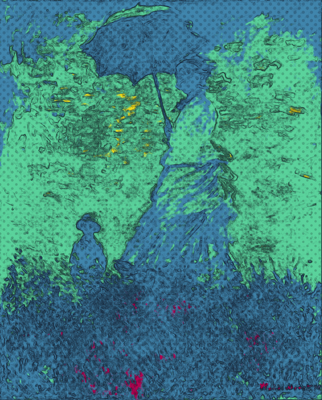

In [1]:
import io
from PIL import Image

import brushcue as bc

palette = 0
color_levels = 4
outline_strength = 0.65
halftone_amount = 0.25
input_image = bc.Composition.monet_women_with_parasol()
bounds = input_image.bounds()
reference_scale = (
    bc.Float.max(1.0, bc.Float.min(bounds.width(), bounds.height())) / 1000.0
)
dot_spacing = bc.Float.max(4.0, (reference_scale * 18.0))
graph = input_image.spacial_effect_shader(
    "let lo = image_bounds.xy + vec2f(0.5);\nlet hi = image_bounds.zw - vec2f(0.5);\nlet p = clamp(position, lo, hi);\nlet source = sample(p);\nif (source.a <= 0.0) { return vec4f(0.0); }\nlet center = luma(source.rgb);\nlet step_size = max(1.0, reference_scale * 2.0);\n// Alpha-weighted smoothing prevents noisy islands in the posterized colors.\nvar total = 0.0;\nvar weight = 0.0;\nfor (var y = -2; y <= 2; y = y + 1) {\n    for (var x = -2; x <= 2; x = x + 1) {\n        let offset = vec2f(f32(x), f32(y));\n        let q = clamp(floor(p + offset * step_size) + vec2f(0.5), lo, hi);\n        let c = sample(q);\n        let w = exp(-dot(offset, offset) * 0.5) * c.a;\n        total += luma(c.rgb) * w;\n        weight += w;\n    }\n}\nlet gray = select(center, total / max(weight, 0.0001), weight > 0.0001);\nlet levels = max(2.0, color_levels);\nlet value = floor(clamp(gray, 0.0, 1.0) * (levels - 1.0) + 0.5) / (levels - 1.0);\nvar shadow = vec3f(0.70, 0.015, 0.32);\nvar middle = vec3f(0.03, 0.78, 0.86);\nvar highlight = vec3f(1.0, 0.92, 0.12);\nif (palette > 0.5 && palette < 1.5) {\n    shadow = vec3f(0.055, 0.09, 0.23);\n    middle = vec3f(0.95, 0.12, 0.14);\n    highlight = vec3f(1.0, 0.94, 0.78);\n}\nif (palette >= 1.5) {\n    shadow = vec3f(0.25, 0.045, 0.48);\n    middle = vec3f(0.64, 0.88, 0.10);\n    highlight = vec3f(1.0, 0.77, 0.58);\n}\nvar color = select(mix(shadow, middle, value * 2.0), mix(middle, highlight, (value - 0.5) * 2.0), value >= 0.5);\n// Sobel contours sample pixel centers so transparent hidden colors cannot bleed.\nlet tl = tone(sample(clamp(floor(p + vec2f(-step_size, -step_size)) + vec2f(0.5), lo, hi)), center);\nlet t = tone(sample(clamp(floor(p + vec2f(0.0, -step_size)) + vec2f(0.5), lo, hi)), center);\nlet tr = tone(sample(clamp(floor(p + vec2f(step_size, -step_size)) + vec2f(0.5), lo, hi)), center);\nlet l = tone(sample(clamp(floor(p + vec2f(-step_size, 0.0)) + vec2f(0.5), lo, hi)), center);\nlet r = tone(sample(clamp(floor(p + vec2f(step_size, 0.0)) + vec2f(0.5), lo, hi)), center);\nlet bl = tone(sample(clamp(floor(p + vec2f(-step_size, step_size)) + vec2f(0.5), lo, hi)), center);\nlet b = tone(sample(clamp(floor(p + vec2f(0.0, step_size)) + vec2f(0.5), lo, hi)), center);\nlet br = tone(sample(clamp(floor(p + vec2f(step_size, step_size)) + vec2f(0.5), lo, hi)), center);\nlet edge = smoothstep(0.15, 0.65, length(vec2f(tr + 2.0 * r + br - tl - 2.0 * l - bl, bl + 2.0 * b + br - tl - 2.0 * t - tr)));\n// Rotated screen dots are antialiased analytically for compute rendering.\nlet uv = p - image_bounds.xy;\nlet screen = vec2f(uv.x + uv.y, uv.y - uv.x) * 0.7071067812;\nlet cell = fract(screen / dot_spacing) - vec2f(0.5);\nlet distance = length(cell) * dot_spacing;\nlet radius = dot_spacing * 0.36 * sqrt(max(0.0, 1.0 - gray));\nlet dot_ink = (1.0 - smoothstep(max(0.0, radius - 0.55), radius + 0.55, distance)) * (1.0 - smoothstep(0.85, 1.0, gray));\nlet ink = vec3f(0.035, 0.025, 0.07);\ncolor = mix(color, ink, dot_ink * halftone_amount * 0.75);\ncolor = mix(color, ink, edge * outline_strength);\nreturn vec4f(clamp(color, vec3f(0.0), vec3f(1.0)), source.a);",
    "fn luma(rgb: vec3f) -> f32 {\n    return dot(clamp(rgb, vec3f(0.0), vec3f(1.0)), vec3f(0.299, 0.587, 0.114));\n}\n// Ignore colors hidden in transparent pixels when measuring contours.\nfn tone(c: vec4f, fallback: f32) -> f32 {\n    return mix(fallback, luma(c.rgb), clamp(c.a, 0.0, 1.0));\n}",
    0.0,
    bc.Dictionary.create()
    .add("image_bounds", bounds)
    .add("reference_scale", reference_scale)
    .add("dot_spacing", dot_spacing)
    .add("palette", bc.Int.to_float(palette))
    .add("color_levels", bc.Int.to_float(color_levels))
    .add("outline_strength", outline_strength)
    .add("halftone_amount", halftone_amount),
    bc.ColorRepresentation.srgb(),
).crop(bounds)

ctx = bc.Context()
composition = graph.execute(ctx)
data_bytes = composition.to_image_bytes(ctx)
img = Image.open(io.BytesIO(data_bytes))
img.thumbnail((400, 400))  # Remove this line for full resolution
img
